# 15. Gradient boosting and the Huber loss

Gradient boosting builds a model as a sum of small trees, each fitted to the residuals of the sum so far. With the squared loss an outlier produces a large residual that the next trees follow. Clipping the residuals, which corresponds to the Huber loss of Lecture 5, limits that influence. The lecture compares the two losses on a synthetic hardness curve with two gross outliers.

## Learning objectives

1. State gradient boosting as a sum of trees fitted in stages (`trees_ensembles.GradientBoostingRegressor`).
2. Follow the decrease of the training error with the number of stages on a synthetic hardness curve of a binary alloy.
3. Derive and apply the clipped residuals of the Huber loss (`trees_ensembles.HuberGradientBoostingRegressor`).
4. Compare the two losses on data with gross outliers, for several learning rates and thresholds.

**Time:** about 60 min

In [1]:
try:                      # use the installed package, or the copy in this repository
    import engml_2_applied
except ImportError:
    import pathlib, subprocess, sys
    for _root in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (_root / "engml_2_applied" / "__init__.py").exists():
            sys.path.insert(0, str(_root))
            break
    else:                 # on Google Colab: install from GitHub
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "git+https://github.com/ktwyw/engml-2-applied.git"], check=True)
    import engml_2_applied

import inspect
import numpy as np
import matplotlib.pyplot as plt
from engml_2_applied import (clustering_phases, constants, descriptors, dim_reduction, linear_physics,
                             trees_ensembles, uncertainty)
from engml_2_applied.plotting import panel_label, use_style

use_style()

def show_source(obj):
    """Return the source code of a library function or class."""
    return inspect.getsource(obj)

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## 1. Principles and governing equations
Given a differentiable loss function $\mathcal{L}(y, F)$, **functional gradient boosting (Friedman, 2001)** constructs an additive surrogate $F_M(\mathbf{x}) = F_0 + \eta\sum_{m=1}^M h_m(\mathbf{x})$ with shrinkage learning rate $\eta \in (0, 1]$ and shallow regression trees $h_m(\mathbf{x})$ (depth $1$–$3$):
$$F_0 = \arg\min_\gamma \sum_{i=1}^N \mathcal{L}(y_i, \gamma) = \begin{cases} \bar{y} & \text{for } L_2\text{ loss} \\ \mathrm{median}(\mathbf{y}) & \text{for Huber / }L_1\text{ loss} \end{cases} \tag{1.1}$$
At stage $m = 1, \dots, M$, we evaluate the **pseudo-residual vector** $\mathbf{r}_m \in \mathbb{R}^N$ (the negative functional gradient in function space evaluated at $F_{m-1}$):
$$r_{i,m} = -\left[\frac{\partial \mathcal{L}(y_i, F)}{\partial F}\right]_{F = F_{m-1}(\mathbf{x}_i)} = \begin{cases} y_i - F_{m-1}(\mathbf{x}_i) & \text{for } \mathcal{L}_{L_2} = \frac{1}{2}(y - F)^2 \\ \mathrm{clip}\!\left(y_i - F_{m-1}(\mathbf{x}_i),\, -\delta,\, +\delta\right) & \text{for Huber loss } \mathcal{L}_\delta(y - F) \end{cases} \tag{1.2}$$
Fitting a shallow CART tree $h_m(\mathbf{x})$ to $\{(\mathbf{x}_i, r_{i,m})\}_{i=1}^N$ and updating:
$$F_m(\mathbf{x}) = F_{m-1}(\mathbf{x}) + \eta\,h_m(\mathbf{x}) \tag{1.3}$$
contracts residuals geometrically ($r_m = (1 - \eta)^m r_0$ for exact stage fits) while the clipping of the Huber loss limits the influence of gross outliers on the splits of the trees.

In [2]:
heading("Demonstration 1: Stagewise L2 Boosting on a Synthetic Hardness Curve of a Binary Alloy")
x_Ni = np.linspace(0.0, 1.0, 45)
# Synthetic hardness curve of a binary alloy: a parabolic term plus an asymmetric term (assumed constants, HV):
HV_true = 65.0 + 180.0 * x_Ni * (1.0 - x_Ni) + 35.0 * (x_Ni ** 2)

mses_stage = []
for m_trees in [1, 5, 15, 35]:
    gbm = trees_ensembles.GradientBoostingRegressor(n_estimators=m_trees, learning_rate=0.2, max_depth=2).fit(x_Ni, HV_true)
    mses_stage.append(float(np.mean((gbm.predict(x_Ni) - HV_true) ** 2)))
    print(f"Stage M = {m_trees:2d} shallow trees (depth=2) | Hardness MSE = {mses_stage[-1]:.4f} HV^2")

assert all(mses_stage[i] > mses_stage[i + 1] for i in range(len(mses_stage) - 1)) and mses_stage[-1] < 1.0


Demonstration 1: Stagewise L2 Boosting on a Synthetic Hardness Curve of a Binary Alloy
Stage M =  1 shallow trees (depth=2) | Hardness MSE = 160.1599 HV^2
Stage M =  5 shallow trees (depth=2) | Hardness MSE = 39.8514 HV^2
Stage M = 15 shallow trees (depth=2) | Hardness MSE = 1.9629 HV^2
Stage M = 35 shallow trees (depth=2) | Hardness MSE = 0.0513 HV^2


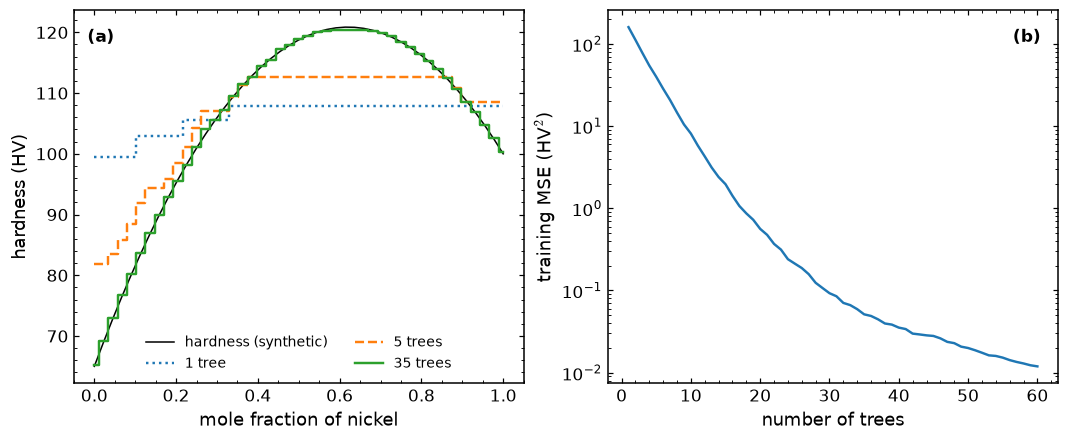

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
ax1.plot(x_Ni, HV_true, "k-", lw=1.0, label="hardness (synthetic)")
for m_trees, style in [(1, ":"), (5, "--"), (35, "-")]:
    gbm_f = trees_ensembles.GradientBoostingRegressor(n_estimators=m_trees, learning_rate=0.2, max_depth=2).fit(x_Ni, HV_true)
    ax1.step(x_Ni, gbm_f.predict(x_Ni), style, where="mid", label=f"{m_trees} tree" + ("s" if m_trees > 1 else ""))
ax1.set_xlabel("mole fraction of nickel"); ax1.set_ylabel("hardness (HV)"); ax1.legend(fontsize=9, loc="lower center", ncol=2); panel_label(ax1, "(a)")
m_list = np.arange(1, 61); mse_m = []
for m_trees in m_list:
    gbm_f = trees_ensembles.GradientBoostingRegressor(n_estimators=int(m_trees), learning_rate=0.2, max_depth=2).fit(x_Ni, HV_true)
    mse_m.append(np.mean((gbm_f.predict(x_Ni) - HV_true) ** 2))
ax2.semilogy(m_list, mse_m, "-"); ax2.set_xlabel("number of trees"); ax2.set_ylabel("training MSE (HV$^2$)"); panel_label(ax2, "(b)", x=0.9)
plt.show()

**Figure 15.1.** (a) Gradient boosting of trees of depth 2 on a synthetic hardness curve of a binary alloy, after 1, 5 and 35 trees with a learning rate of 0.2. (b) The training error against the number of trees.

**What Demonstration 1 shows.** One tree of depth 2 has four constant pieces and represents the smooth hardness curve poorly (mean squared error $160\;\mathrm{HV}^2$). Adding shallow trees one after another, each fitted to the residual of the sum so far, brings the error down to $2.0\;\mathrm{HV}^2$ after 15 trees and $0.05\;\mathrm{HV}^2$ after 35. The hardness curve is a synthetic parabola in the composition.

---

## 2. Numerical walkthrough
Let us compare the stage-1 pseudo-residuals $r_{i,1}$ of $L_2$ gradient boosting versus Huber-clipped gradient boosting ($\delta = 5.0\;\mathrm{HV}$) when two Vickers microhardness measurements hit a brittle oxide inclusion ($+250\;\mathrm{HV}$ spike).

In [4]:
heading("Demonstration 2: Unclipped L2 Pseudo-Residuals vs. Huber-Clipped Pseudo-Residuals")
rng = np.random.default_rng(42)
HV_noisy = HV_true + rng.normal(0.0, 1.8, size=len(x_Ni))
HV_spiked = HV_noisy.copy()
HV_spiked[0] += 250.0
HV_spiked[-1] += 250.0

r1_l2 = HV_spiked - float(np.mean(HV_spiked))
r1_huber = np.clip(HV_spiked - float(np.median(HV_spiked)), -5.0, 5.0)
print(f"Stage-1 L2 initial baseline mean(y)      = {np.mean(HV_spiked):.2f} HV | Spike pseudo-residual r_0 = {r1_l2[0]:+.2f} HV")
print(f"Stage-1 Huber initial baseline median(y) = {np.median(HV_spiked):.2f} HV | Clipped pseudo-residual r_0 = {r1_huber[0]:+.2f} HV")
assert abs(r1_l2[0]) > 180.0 and abs(r1_huber[0]) == 5.0


Demonstration 2: Unclipped L2 Pseudo-Residuals vs. Huber-Clipped Pseudo-Residuals
Stage-1 L2 initial baseline mean(y)      = 117.33 HV | Spike pseudo-residual r_0 = +198.22 HV
Stage-1 Huber initial baseline median(y) = 111.94 HV | Clipped pseudo-residual r_0 = +5.00 HV


**What Demonstration 2 shows.** With the squared loss the two spikes of $+250\;\mathrm{HV}$ raise the starting value, the mean, to $117.3\;\mathrm{HV}$ (the median is $111.9$), and leave residuals of $+198\;\mathrm{HV}$ at the spikes, which the first trees are then built to fit. With the Huber loss the start is the median and the residuals of the spikes are clipped to $+5\;\mathrm{HV}$.

---

## 3. Worked case study
Let us now compare the full 25-stage $L_2$ gradient boosting model against the 25-stage Huber-clipped gradient boosting model (`trees_ensembles.HuberGradientBoostingRegressor`) on `HV_spiked`, evaluating RMSE against the curve behind the data, `HV_true`.

In [5]:
heading("Demonstration 3: L2 GBM vs. Huber-Clipped GBM Benchmark on Outlier-Corrupted Alloy Data")
gbm_l2 = trees_ensembles.GradientBoostingRegressor(n_estimators=25, learning_rate=0.15, max_depth=2).fit(x_Ni, HV_spiked)
gbm_huber = trees_ensembles.HuberGradientBoostingRegressor(n_estimators=25, learning_rate=0.15, max_depth=2, delta=5.0).fit(x_Ni, HV_spiked)

rmse_l2 = float(np.sqrt(np.mean((gbm_l2.predict(x_Ni) - HV_true) ** 2)))
rmse_huber = float(np.sqrt(np.mean((gbm_huber.predict(x_Ni) - HV_true) ** 2)))
print(f"RMSE vs the true curve under 2 gross spikes: L2 GBM = {rmse_l2:.3f} HV -> Huber Clipped GBM = {rmse_huber:.3f} HV")
assert rmse_huber < 0.35 * rmse_l2


Demonstration 3: L2 GBM vs. Huber-Clipped GBM Benchmark on Outlier-Corrupted Alloy Data
RMSE vs the true curve under 2 gross spikes: L2 GBM = 51.234 HV -> Huber Clipped GBM = 12.160 HV


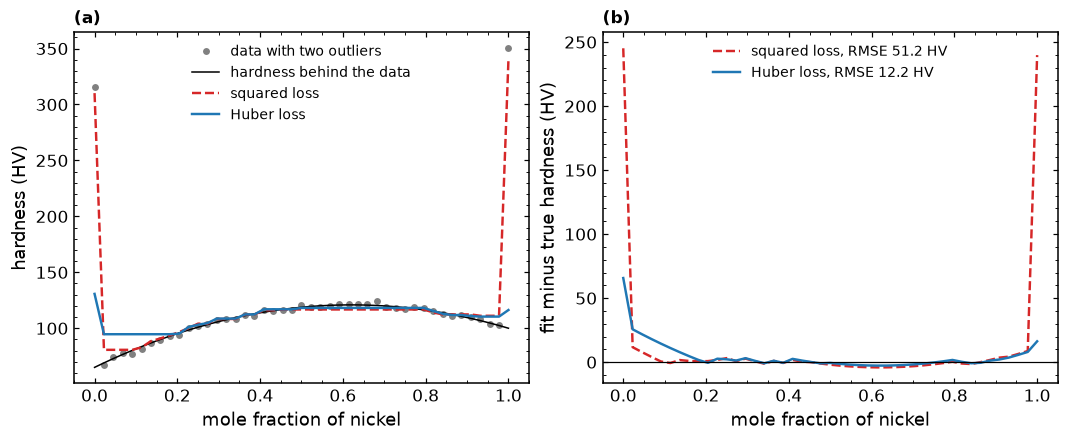

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
ax1.plot(x_Ni, HV_spiked, "o", ms=3.5, color="0.5", label="data with two outliers")
ax1.plot(x_Ni, HV_true, "k-", lw=1.0, label="hardness behind the data")
ax1.plot(x_Ni, gbm_l2.predict(x_Ni), "--", color="C3", label="squared loss")
ax1.plot(x_Ni, gbm_huber.predict(x_Ni), "-", color="C0", label="Huber loss")
ax1.set_xlabel("mole fraction of nickel"); ax1.set_ylabel("hardness (HV)"); ax1.legend(fontsize=9, loc="upper center"); ax1.set_title("(a)", loc="left", fontweight="bold")
ax2.plot(x_Ni, gbm_l2.predict(x_Ni) - HV_true, "--", color="C3", label=f"squared loss, RMSE {rmse_l2:.1f} HV")
ax2.plot(x_Ni, gbm_huber.predict(x_Ni) - HV_true, "-", color="C0", label=f"Huber loss, RMSE {rmse_huber:.1f} HV")
ax2.axhline(0.0, color="k", lw=0.8)
ax2.set_xlabel("mole fraction of nickel"); ax2.set_ylabel("fit minus true hardness (HV)"); ax2.legend(fontsize=9, loc="upper center"); ax2.set_title("(b)", loc="left", fontweight="bold")
plt.show()

**Figure 15.2.** (a) The hardness data with an outlier of +250 HV at each end, and the fits of 25 boosted trees with the squared loss and with the Huber loss. (b) The errors of the two fits with respect to the curve behind the data.

**What Demonstration 3 shows.** Against the curve that generated the data, boosting with the squared loss has an error of $51.2\;\mathrm{HV}$, because it fits the two spikes; with the Huber loss the error is $12.2\;\mathrm{HV}$, four times smaller. The spikes still leave a trace: the clipped loss limits their influence and does not remove it.

---

## 4. What if: sensitivity to the parameters
How do the shrinkage learning rate $\eta \in \{0.05, 0.15, 0.40\}$ and Huber clipping threshold $\delta \in \{2.0, 5.0, 25.0, 250.0\}$ control the accuracy and robustness of Huber gradient boosting?

In [7]:
heading("Demonstration 4: Shrinkage Learning Rate eta & Huber Clipping Threshold delta Sweep")
print(f"{'Shrinkage eta':>13s} | {'Huber delta [HV]':>16s} | {'RMSE vs True Alloy Curve [HV]':>29s}")
print("-" * 64)
for lr, d_h in [(0.05, 5.0), (0.15, 2.0), (0.15, 5.0), (0.15, 25.0), (0.15, 250.0), (0.40, 5.0)]:
    gb_s = trees_ensembles.HuberGradientBoostingRegressor(n_estimators=30, learning_rate=lr, max_depth=2, delta=d_h).fit(x_Ni, HV_spiked)
    err_s = float(np.sqrt(np.mean((gb_s.predict(x_Ni) - HV_true) ** 2)))
    print(f"{lr:13.2f} | {d_h:16.1f} | {err_s:29.3f}")


Demonstration 4: Shrinkage Learning Rate eta & Huber Clipping Threshold delta Sweep
Shrinkage eta | Huber delta [HV] | RMSE vs True Alloy Curve [HV]
----------------------------------------------------------------
         0.05 |              5.0 |                        13.778
         0.15 |              2.0 |                        13.277
         0.15 |              5.0 |                        12.155


         0.15 |             25.0 |                        29.712
         0.15 |            250.0 |                        51.632
         0.40 |              5.0 |                        17.042


**What Demonstration 4 shows.** With $\delta = 250\;\mathrm{HV}$ nothing is clipped and the error is that of the squared loss ($51.6\;\mathrm{HV}$); with $\delta = 25\;\mathrm{HV}$ it is $29.7$, and with $\delta = 5$ and a learning rate of $0.15$ it is smallest, $12.2\;\mathrm{HV}$. The learning rate matters less: $13.8\;\mathrm{HV}$ at $0.05$ and $17.0\;\mathrm{HV}$ at $0.40$.

---

## Inside the algorithm
Below we run a standalone 10-line Huber functional gradient boosting loop in pure NumPy and verify digit-for-digit agreement with `trees_ensembles.HuberGradientBoostingRegressor`.

In [8]:
heading("Inside the Algorithm: By-Hand Huber Boosting Loop vs. the Library")
f0_hand = float(np.median(HV_spiked))
pred_hand = np.full_like(HV_spiked, f0_hand)
for _ in range(25):
    p_res = np.clip(HV_spiked - pred_hand, -5.0, 5.0)
    t_stage = trees_ensembles.DecisionTreeRegressor(max_depth=2, min_samples_split=6).fit(x_Ni, p_res)
    pred_hand += 0.15 * t_stage.predict(x_Ni)
diff_hgbm = float(np.max(np.abs(pred_hand - gbm_huber.predict(x_Ni))))
print("by hand (pure NumPy) pred[:5]:", np.round(pred_hand[:5], 5))
print("library (engml_2_applied)      pred[:5]:", np.round(gbm_huber.predict(x_Ni)[:5], 5))
print(f"Max discrepancy              : {diff_hgbm:.2e}")
assert diff_hgbm < 1e-14


Inside the Algorithm: By-Hand Huber Boosting Loop vs. the Library
by hand (pure NumPy) pred[:5]: [130.69474  94.6327   94.6327   94.6327   94.6327 ]
library (engml_2_applied)      pred[:5]: [130.69474  94.6327   94.6327   94.6327   94.6327 ]
Max discrepancy              : 0.00e+00


## Exercises

1. **Verify a result.** For a 0-split constant stump update $h_m(x) = r_{m-1}$, prove and verify numerically that after $M = 20$ boosting stages with shrinkage $\eta = 0.15$ and initial residual $r_0 = 10.0$, the stage-$M$ residual equals the exact geometric contraction $(1 - \eta)^M r_0$ to machine precision.
2. **Find how it fails.** Examine a learning rate that is too large: train `GradientBoostingRegressor(n_estimators=15, learning_rate=2.10, max_depth=2)` on `HV_true` and compare its error with that of $\eta = 0.20$. For $\eta > 2$ each stage overshoots by more than the residual it corrects ($1 - \eta = -1.1$), so the residual changes sign and grows.
3. **Write it yourself.** Implement an **early-stopping validation monitor** `gbm_early_stopping(X_tr, y_tr, X_val, y_val, max_stages=40, lr=0.15, max_depth=2)` that evaluates held-out validation MSE at every boosting stage $m = 1, \dots, M_{\max}$ and returns the stage $m^*$ minimizing validation error. Verify it on noisy Nordheim alloy train/validation data.

The cell below works Exercise 1 as a first check; all three are solved in the solutions notebook of this lecture.

In [9]:
heading("Exercise 1: Geometric Residual Contraction r_M = (1 - eta)^M r_0 Verification")
eta, M = 0.15, 20
r0 = 10.0
r_iter = r0
for _ in range(M):
    r_iter = r_iter - eta * r_iter
r_exact = ((1.0 - eta) ** M) * r0
print(f"After M={M} stages: Iterative residual = {r_iter:.8f} == Analytical (1-eta)^M r0 = {r_exact:.8f}")
assert np.isclose(r_iter, r_exact, rtol=1e-15)


Exercise 1: Geometric Residual Contraction r_M = (1 - eta)^M r_0 Verification
After M=20 stages: Iterative residual = 0.38759531 == Analytical (1-eta)^M r0 = 0.38759531
